--- 52-Week Fish Stock Simulation (First 5 Weeks) ---
 Week  Start_Stock  Growth  Harvest  End_Stock
    1      4000.00  960.00   320.00    4640.00
    2      4640.00  994.82   371.20    5263.62
    3      5263.62  997.22   421.09    5839.75
    4      5839.75  971.79   467.18    6344.36
    5      6344.36  927.71   507.55    6764.52


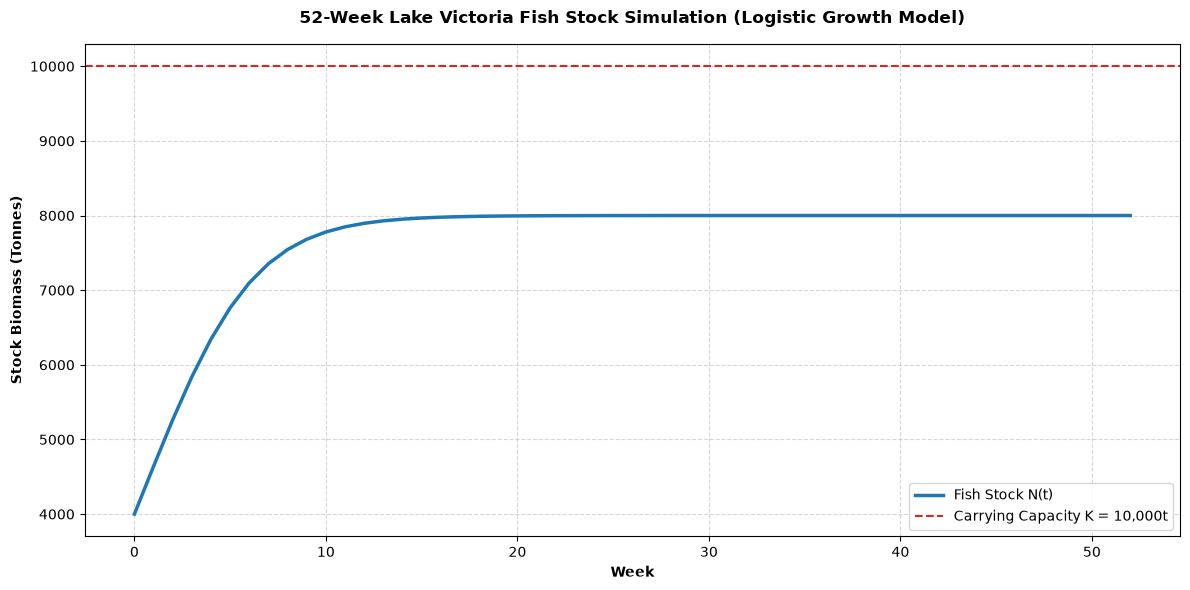

In [6]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Ensure src path is accessible
project_src = r"D:\MSCS Stuff\kisomose\miniiproject 1\mini-projects-OOP\src"
if project_src not in sys.path:
    sys.path.insert(0, project_src)

from fish_model import FishStock

# Parameters specified
R_RATE = 0.4
CARRYING_CAPACITY = 10000.0
INITIAL_STOCK = 4000.0
WEEKS = 52
HARVEST_COEFF = 0.08  # Proportional harvesting rate (h)

# Instantiate and simulate
model = FishStock(
    initial_stock=INITIAL_STOCK,
    carrying_capacity=CARRYING_CAPACITY,
    growth_rate=R_RATE
)

df_stock, df_activity = model.simulate_weeks(weeks=WEEKS, harvest_coeff=HARVEST_COEFF)

print("--- 52-Week Fish Stock Simulation (First 5 Weeks) ---")
print(df_activity.head().to_string(index=False))

# Plotting the 52-week trajectory
plt.figure(figsize=(12, 6))
plt.plot(df_stock['Week'], df_stock['Stock_N'], label='Fish Stock N(t)', color='tab:blue', linewidth=2.5)
plt.axhline(CARRYING_CAPACITY, color='tab:red', linestyle='--', label=f'Carrying Capacity K = {CARRYING_CAPACITY:,.0f}t')
plt.xlabel('Week', fontweight='bold')
plt.ylabel('Stock Biomass (Tonnes)', fontweight='bold')
plt.title('52-Week Lake Victoria Fish Stock Simulation (Logistic Growth Model)', fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [10]:
import importlib
import fish_model

# Force reload the module so Python picks up PriceModel from src/fish_model.py
importlib.reload(fish_model)

from fish_model import FishStock, PriceModel

# Now run your instantiation code again
price_model = PriceModel(initial_price=12000.0, min_price=9000.0, max_price=16000.0, seed=42)
weekly_prices = price_model.simulate_prices(weeks=WEEKS, volatility=300.0)

print("Price model successfully initialized!")

Price model successfully initialized!


In [11]:
# Instantiate Price Model
price_model = PriceModel(initial_price=12000.0, min_price=9000.0, max_price=16000.0, seed=42)
weekly_prices = price_model.simulate_prices(weeks=WEEKS, volatility=300.0)

# Extract harvest in tonnes from previous FishStock simulation
harvest_tonnes = df_activity['Harvest'].values

# Convert harvest to kilograms (1 tonne = 1,000 kg)
harvest_kg = harvest_tonnes * 1000.0

# Compute weekly revenue: Revenue = harvest (kg) * price (UGX/kg)
weekly_revenue_ugx = harvest_kg * weekly_prices

df_revenue = pd.DataFrame({
    "Week": np.arange(1, WEEKS + 1),
    "Stock_Start_t": df_activity['Start_Stock'],
    "Harvest_t": harvest_tonnes,
    "Harvest_kg": harvest_kg,
    "Price_UGX_per_kg": np.round(weekly_prices, 2),
    "Weekly_Revenue_UGX": np.round(weekly_revenue_ugx, 2)
})

print("--- 52-Week Harvest and Revenue Model (First 5 Weeks) ---")
print(df_revenue.head().to_string(index=False))

total_annual_revenue = df_revenue['Weekly_Revenue_UGX'].sum()
print(f"\nTotal Annual Export Revenue: UGX {total_annual_revenue:,.2f}")

--- 52-Week Harvest and Revenue Model (First 5 Weeks) ---
 Week  Stock_Start_t  Harvest_t  Harvest_kg  Price_UGX_per_kg  Weekly_Revenue_UGX
    1        4000.00     320.00    320000.0          12000.00        3.840000e+09
    2        4640.00     371.20    371200.0          12149.01        4.509714e+09
    3        5263.62     421.09    421090.0          12107.53        5.098362e+09
    4        5839.75     467.18    467180.0          12301.84        5.747174e+09
    5        6344.36     507.55    507550.0          12758.75        6.475704e+09

Total Annual Export Revenue: UGX 348,861,664,623.44


In [12]:
import numpy as np
import pandas as pd

# Assuming df_revenue from the previous step exists with 'Weekly_Revenue_UGX'
revenues = df_revenue['Weekly_Revenue_UGX']

rev_mean = revenues.mean()
rev_median = revenues.median()
rev_var = revenues.var(ddof=1)
rev_std = revenues.std(ddof=1)
rev_cv = rev_std / rev_mean if rev_mean > 0 else 0.0

print("--- Export Revenue Statistical Profile ---")
print(f"Mean Revenue:               UGX {rev_mean:,.2f}")
print(f"Median Revenue:             UGX {rev_median:,.2f}")
print(f"Revenue Variance:           UGX^2 {rev_var:,.2e}")
print(f"Revenue Standard Deviation: UGX {rev_std:,.2f}")
print(f"Coefficient of Variation:   {rev_cv:.4f} ({rev_cv*100:.2f}%)")

--- Export Revenue Statistical Profile ---
Mean Revenue:               UGX 6,708,878,165.84
Median Revenue:             UGX 6,731,272,029.76
Revenue Variance:           UGX^2 8.95e+17
Revenue Standard Deviation: UGX 945,938,672.66
Coefficient of Variation:   0.1410 (14.10%)


In [13]:
import importlib
import fish_model
importlib.reload(fish_model)
from fish_model import FishStock, PriceModel, RiskAssessor

# 1. Setup Monte Carlo parameters
NUM_SIMULATIONS = 1000
WEEKS = 52

# Retrieve baseline harvest schedule from previous FishStock simulation (in kg)
harvest_kg_schedule = df_activity['Harvest'].values * 1000.0

# 2. Run Monte Carlo simulation across 1,000 price paths
annual_revenues = np.zeros(NUM_SIMULATIONS)

for i in range(NUM_SIMULATIONS):
    # Initialize PriceModel with unique seed per path for robust stochastic variation
    pm_mc = PriceModel(initial_price=12000.0, min_price=9000.0, max_price=16000.0, seed=1000 + i)
    path_prices = pm_mc.simulate_prices(weeks=WEEKS, volatility=300.0)
    
    # Total annual revenue for path i = sum of (weekly harvest * weekly price)
    annual_revenues[i] = (harvest_kg_schedule * path_prices).sum()

# 3. Compute distribution statistics
mean_annual_rev = annual_revenues.mean()
std_annual_rev = annual_revenues.std(ddof=1)
cv_annual_rev = std_annual_rev / mean_annual_rev

# 4. Risk Assessment and VaR Calculation
assessor = RiskAssessor(low_threshold=0.10, high_threshold=0.25)
risk_label = assessor.classify_risk(cv_annual_rev)
var_5pct = assessor.compute_var(annual_revenues, percentile=5.0)

print("--- Monte Carlo Export Revenue Risk Report (1,000 Paths) ---")
print(f"Mean Annual Revenue:          UGX {mean_annual_rev:,.2f}")
print(f"Standard Deviation:           UGX {std_annual_rev:,.2f}")
print(f"Coefficient of Variation (CV): {cv_annual_rev:.4f} ({cv_annual_rev*100:.2f}%)")
print(f"Assessed Risk Category:       {risk_label}")
print("-" * 60)
print(f"5% Value-at-Risk (VaR):       UGX {var_5pct:,.2f}")

--- Monte Carlo Export Revenue Risk Report (1,000 Paths) ---
Mean Annual Revenue:          UGX 383,568,919,728.69
Standard Deviation:           UGX 38,731,834,439.15
Coefficient of Variation (CV): 0.1010 (10.10%)
Assessed Risk Category:       MODERATE_RISK
------------------------------------------------------------
5% Value-at-Risk (VaR):       UGX 322,097,033,461.54


In [14]:
import numpy as np
import pandas as pd
from fish_model import FishStock, PriceModel, RiskAssessor

# 1. Define scenario parameters
harvest_scenarios = [0.05, 0.10, 0.20, 0.30]
weeks = 52
r_rate = 0.4
k_capacity = 10000.0
initial_stock = 4000.0

# Calculate Theoretical Maximum Sustainable Yield (MSY = r * K / 4)
# For continuous logistic growth, MSY = rK / 4. In discrete terms, it serves as the benchmark.
msy_theoretical = (r_rate * k_capacity) / 4.0

results_summary = []
assessor = RiskAssessor(low_threshold=0.10, high_threshold=0.25)

for h in harvest_scenarios:
    # Simulate stock dynamics for harvest rate h
    fs = FishStock(initial_stock=initial_stock, carrying_capacity=k_capacity, growth_rate=r_rate)
    df_stock_res, df_act_res = fs.simulate_weeks(weeks=weeks, harvest_coeff=h)
    
    # Simulate prices for revenue calculation
    pm = PriceModel(initial_price=12000.0, min_price=9000.0, max_price=16000.0, seed=42)
    prices = pm.simulate_prices(weeks=weeks, volatility=300.0)
    
    harvest_kg = df_act_res['Harvest'].values * 1000.0
    revenues = harvest_kg * prices
    
    total_rev = revenues.sum()
    final_stk = df_stock_res['Stock_N'].iloc[-1]
    
    # Compute CV and risk class
    mean_rev = revenues.mean()
    std_rev = revenues.std(ddof=1)
    cv = std_rev / mean_rev if mean_rev > 0 else 0.0
    risk_class = assessor.classify_risk(cv)
    
    # Average harvest in tonnes per week
    avg_harvest = df_act_res['Harvest'].mean()
    
    results_summary.append({
        "Harvest_Coeff (h)": h,
        "Avg_Harvest_Tonnes": round(avg_harvest, 2),
        "Final_Stock_Tonnes": round(final_stk, 2),
        "Total_Revenue_UGX": round(total_rev, 2),
        "CV": round(cv, 4),
        "Risk_Class": risk_class
    })

df_scenarios = pd.DataFrame(results_summary)

print("--- Scenario Analysis Report ---")
print(f"Theoretical MSY Benchmark (rK / 4): {msy_theoretical:,.2f} tonnes/period equivalent\n")
print(df_scenarios.to_string(index=False))

--- Scenario Analysis Report ---
Theoretical MSY Benchmark (rK / 4): 1,000.00 tonnes/period equivalent

 Harvest_Coeff (h)  Avg_Harvest_Tonnes  Final_Stock_Tonnes  Total_Revenue_UGX     CV    Risk_Class
              0.05              417.59             8750.00       2.379841e+11 0.1491 MODERATE_RISK
              0.10              718.51             7500.00       4.096118e+11 0.1351 MODERATE_RISK
              0.20              978.30             4999.99       5.591403e+11 0.1109 MODERATE_RISK
              0.30              816.56             2503.72       4.724978e+11 0.2298 MODERATE_RISK


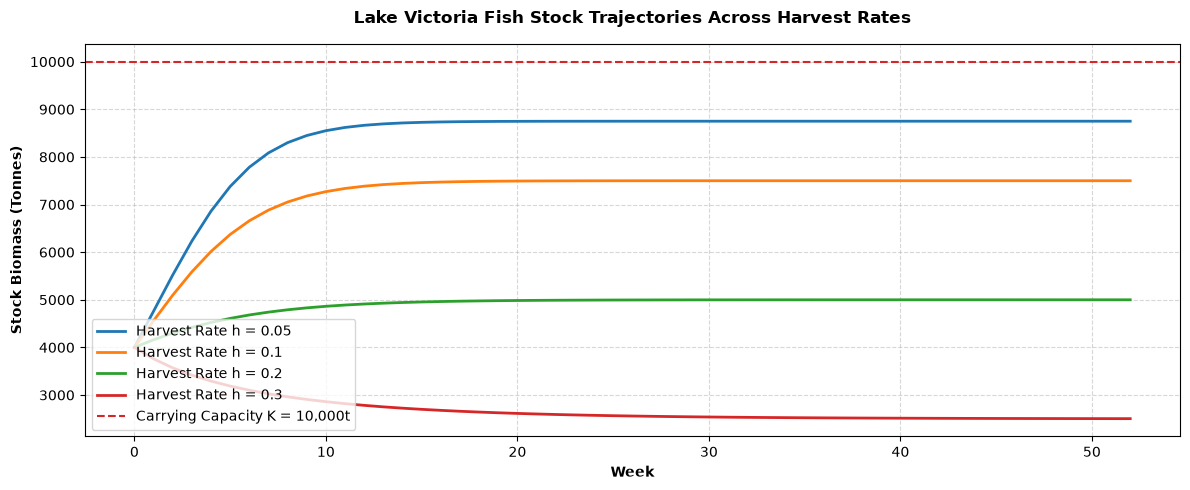

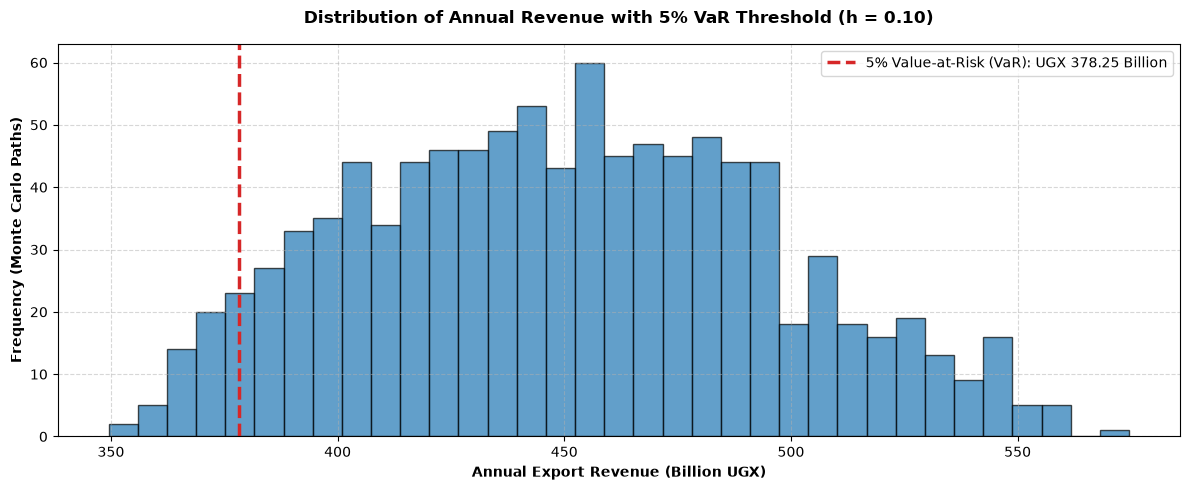

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fish_model import FishStock, PriceModel

# Common parameters
weeks = 52
r_rate = 0.4
k_capacity = 10000.0
initial_stock = 4000.0
harvest_scenarios = [0.05, 0.10, 0.20, 0.30]

# ==========================================
# (a) Stock Trajectories for Each Harvest Rate
# ==========================================
plt.figure(figsize=(12, 5))

for h in harvest_scenarios:
    fs = FishStock(initial_stock=initial_stock, carrying_capacity=k_capacity, growth_rate=r_rate)
    df_stock, _ = fs.simulate_weeks(weeks=weeks, harvest_coeff=h)
    plt.plot(df_stock['Week'], df_stock['Stock_N'], label=f'Harvest Rate h = {h}', linewidth=2)

plt.axhline(k_capacity, color='tab:red', linestyle='--', label=f'Carrying Capacity K = {k_capacity:,.0f}t')
plt.xlabel('Week', fontweight='bold')
plt.ylabel('Stock Biomass (Tonnes)', fontweight='bold')
plt.title('Lake Victoria Fish Stock Trajectories Across Harvest Rates', fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

# ==========================================
# (b) Monte Carlo Revenue Histogram & VaR
# ==========================================
NUM_SIMULATIONS = 1000

# Using baseline sustainable harvest schedule (h = 0.10)
fs_base = FishStock(initial_stock=initial_stock, carrying_capacity=k_capacity, growth_rate=r_rate)
_, df_act_base = fs_base.simulate_weeks(weeks=weeks, harvest_coeff=0.10)
harvest_kg_schedule = df_act_base['Harvest'].values * 1000.0

annual_revenues = np.zeros(NUM_SIMULATIONS)
for i in range(NUM_SIMULATIONS):
    pm_mc = PriceModel(initial_price=12000.0, min_price=9000.0, max_price=16000.0, seed=1000 + i)
    path_prices = pm_mc.simulate_prices(weeks=weeks, volatility=300.0)
    annual_revenues[i] = (harvest_kg_schedule * path_prices).sum()

# Compute 5% Value-at-Risk
var_5pct = np.percentile(annual_revenues, 5.0)

plt.figure(figsize=(12, 5))
# Convert revenue to Billion UGX for clean axis scaling
plt.hist(annual_revenues / 1e9, bins=35, color='tab:blue', edgecolor='black', alpha=0.7)
plt.axvline(var_5pct / 1e9, color='tab:red', linestyle='--', linewidth=2.5, 
            label=f'5% Value-at-Risk (VaR): UGX {var_5pct/1e9:,.2f} Billion')

plt.xlabel('Annual Export Revenue (Billion UGX)', fontweight='bold')
plt.ylabel('Frequency (Monte Carlo Paths)', fontweight='bold')
plt.title('Distribution of Annual Revenue with 5% VaR Threshold (h = 0.10)', fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

--- 5-Year Comparative Impact Analysis ---
Continuous Harvesting 5-Year Total Revenue: UGX 2,627,133,905,105.22
Closed Season (8 wks/yr) 5-Year Revenue:  UGX 2,301,399,628,963.60
Revenue Difference:                      UGX -325,734,276,141.62
Final Stock (Continuous):                6,250.00 tonnes
Final Stock (Closed Season):             9,868.01 tonnes


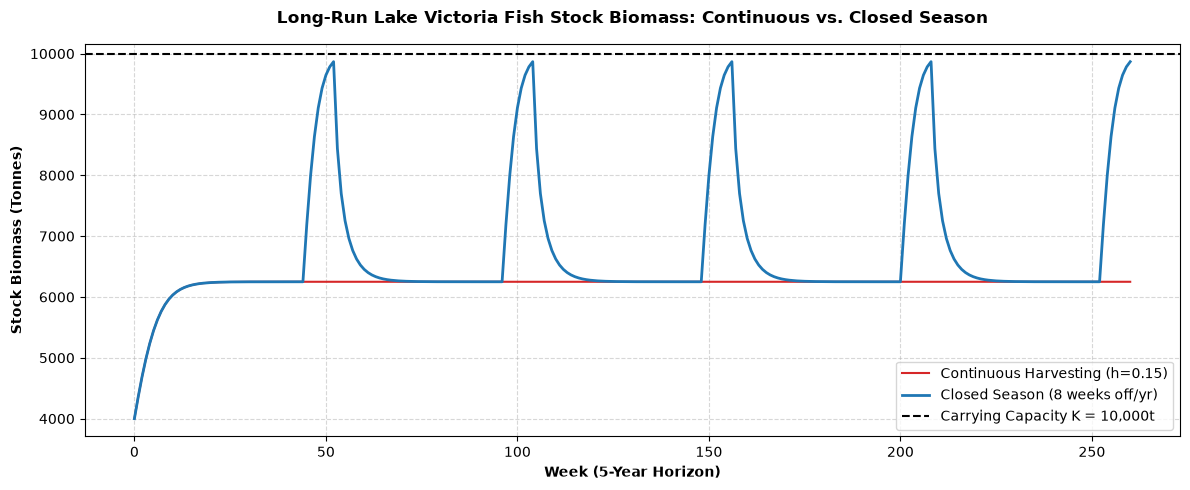

In [16]:
import importlib
import fish_model
importlib.reload(fish_model)
from fish_model import FishStock, PriceModel

# 1. Setup 5-Year Simulation Parameters (5 years * 52 weeks = 260 weeks)
TOTAL_WEEKS = 260
R_RATE = 0.4
CARRYING_CAPACITY = 10000.0
INITIAL_STOCK = 4000.0
BASE_HARVEST_COEFF = 0.15  # Active harvesting pressure

# Simulate without closed season (Continuous Harvesting)
fs_cont = FishStock(initial_stock=INITIAL_STOCK, carrying_capacity=CARRYING_CAPACITY, growth_rate=R_RATE)
df_stock_cont, df_act_cont = fs_cont.simulate_weeks(total_weeks=TOTAL_WEEKS, harvest_coeff=BASE_HARVEST_COEFF, closed_season_weeks=0)

# Simulate with closed season (8 weeks off per year, e.g., starting week 45)
fs_closed = FishStock(initial_stock=INITIAL_STOCK, carrying_capacity=CARRYING_CAPACITY, growth_rate=R_RATE)
df_stock_closed, df_act_closed = fs_closed.simulate_weeks(total_weeks=TOTAL_WEEKS, harvest_coeff=BASE_HARVEST_COEFF, closed_season_weeks=8, closed_season_start=45)

# 2. Generate multi-year price paths for revenue quantification
pm = PriceModel(initial_price=12000.0, min_price=9000.0, max_price=16000.0, seed=42)
multi_year_prices = pm.simulate_prices(weeks=TOTAL_WEEKS, volatility=300.0)

# Calculate long-run revenues
rev_cont = (df_act_cont['Harvest'].values * 1000.0 * multi_year_prices).sum()
rev_closed = (df_act_closed['Harvest'].values * 1000.0 * multi_year_prices).sum()

print("--- 5-Year Comparative Impact Analysis ---")
print(f"Continuous Harvesting 5-Year Total Revenue: UGX {rev_cont:,.2f}")
print(f"Closed Season (8 wks/yr) 5-Year Revenue:  UGX {rev_closed:,.2f}")
print(f"Revenue Difference:                      UGX {rev_closed - rev_cont:,.2f}")
print(f"Final Stock (Continuous):                {df_stock_cont['Stock_N'].iloc[-1]:,.2f} tonnes")
print(f"Final Stock (Closed Season):             {df_stock_closed['Stock_N'].iloc[-1]:,.2f} tonnes")

# 3. Plotting 5-Year Stock Comparison
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df_stock_cont['Week'], df_stock_cont['Stock_N'], label='Continuous Harvesting (h=0.15)', color='tab:red', linewidth=1.5)
plt.plot(df_stock_closed['Week'], df_stock_closed['Stock_N'], label='Closed Season (8 weeks off/yr)', color='tab:blue', linewidth=2)
plt.axhline(CARRYING_CAPACITY, color='black', linestyle='--', label=f'Carrying Capacity K = {CARRYING_CAPACITY:,.0f}t')
plt.xlabel('Week (5-Year Horizon)', fontweight='bold')
plt.ylabel('Stock Biomass (Tonnes)', fontweight='bold')
plt.title('Long-Run Lake Victoria Fish Stock Biomass: Continuous vs. Closed Season', fontweight='bold', pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()